In [1]:
import numpy as np
from pathlib import Path
import os
import re
RESULTS_PATH =Path("./results_mlp_norm/")
ESTIMATOR_PATH = RESULTS_PATH / "estimators"
MCMC_PATH = RESULTS_PATH / "mcmc"
PLOTS_PATH = RESULTS_PATH / "plots"
if not os.path.exists(PLOTS_PATH):
    os.makedirs(PLOTS_PATH)
estimator_files = os.listdir(ESTIMATOR_PATH)
pattern = r"estimator_marginal_(\-?\d+)_quantile_([0-9.]+)/estimator\.yaml"
found_marginals = set()
found_quantiles = set()
for fname in estimator_files:
    match = re.match(pattern, fname + "/estimator.yaml")
    if match:
        found_marginals.add(int(match.group(1)))
        found_quantiles.add(float(match.group(2)))
marginals = sorted(list(found_marginals))
quantiles = sorted(list(found_quantiles))[::-1]

print("Loading results for quantiles =", quantiles, "and marginals =", marginals)
n_marginals = len([m for m in marginals if m != -1])
par_names = ["$\mu_{"+str(i+1)+"}$" for i in range(n_marginals)]
model_name = "gauss"



all_datas = {"true_posterior": dict(np.load(MCMC_PATH / f"mcmc_true.npz", allow_pickle=True)["true_posterior"].item())["samples"]}
for quantile in quantiles:
    all_datas[quantile] = {}
    for marginal in marginals:
        all_datas[quantile][marginal] = {}
        for method in ["nre_standard", "nre_corrected"]:
            all_datas[quantile][marginal][method] = dict(np.load(MCMC_PATH / f"mcmc_marginal_{marginal}_quantile_{quantile}.npz", allow_pickle=True)[method].item())["samples"]


from abcnre.inference import load_estimator_from_yaml
estimators = {}
for quantile in quantiles:
    estimators[quantile] = {}
    for marginal in marginals:
        estimators[quantile][marginal] = load_estimator_from_yaml(ESTIMATOR_PATH / f"estimator_marginal_{marginal}_quantile_{quantile}/estimator.yaml")
        


Loading results for quantiles = [1.0, 0.5, 0.1, 0.05, 0.01] and marginals = [0]


INFO:abcnre.training.config:Loaded configuration from results_mlp_norm/estimators/estimator_marginal_0_quantile_1.0/estimator_classif_config.yaml
INFO:abcnre.simulation.io:Loaded model: GaussGaussMultiDimModel
INFO:abcnre.simulation.io:Loaded observed data from: results_mlp_norm/estimators/estimator_marginal_0_quantile_1.0/estimator_simulator_observed_data.npy
INFO:abcnre.simulation.simulator:Using provided epsilon = inf
INFO:abcnre.inference.io:Loading trained components...
INFO:abcnre.inference.io:Estimator marked as trained.
INFO:abcnre.inference.io:Paths: ['estimator_classif_config.yaml', 'estimator_classif_params.npz', 'estimator_simulator.yaml', 'estimator_stored_phis.npy', 'estimator_training_history.npy']
INFO:abcnre.inference.io:Loading classifier parameters...
INFO:abcnre.training.registry:Registered networks: MLP, DeepSet, ConditionedDeepSet
INFO:abcnre.training.registry:Created MLP network (from 'MLP') for classifier
INFO:abcnre.training.registry:Network args: {'activation'

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_marginals(all_datas, estimators, abc = True, nre = True, correct_nre = True, true = True, n_samples=10000, save = True, xlims = None, joint = True):
    file_name = f"{RESULTS_PATH}/plots/marginal_joint_{model_name}"
    for quantile in quantiles:
        f, ax = plt.subplots(1,n_marginals, figsize=(5*n_marginals, 5))
        if n_marginals == 1:
            ax = [ax]
        if nre: 
            if joint: joint_nre = all_datas[quantile][-1]["nre_standard"]
            for i in range(n_marginals):
                if joint:sns.kdeplot(joint_nre[:, i].flatten(), ax=ax[i], label="Joint NRE", color="red", linestyle="--")
                sns.kdeplot(all_datas[quantile][i]["nre_standard"].flatten(), ax=ax[i], label=f"Marginal NRE", color = "red")
            file_name+= "_nre"
        if correct_nre:
            if joint:joint_correct_nre = all_datas[quantile][-1]["nre_corrected"]

            for i in range(n_marginals):
                if joint:sns.kdeplot(joint_correct_nre[:, i].flatten(), ax=ax[i], label="Joint Corrected NRE", color="blue", linestyle="--")
                sns.kdeplot(all_datas[quantile][i]["nre_corrected"].flatten(), ax=ax[i], label=f"Marginal Corrected NRE", color="blue")
            file_name+= "_corrected_nre"
        if abc: 
            if joint:joint_abc = estimators[quantile][-1].stored_phis
            for i in range(n_marginals):
                marginal_abc = estimators[quantile][i].stored_phis
                if joint:sns.kdeplot(joint_abc[:n_samples, i].flatten(), ax=ax[i], label="Joint ABC", color="orange", linestyle="--") 
                sns.kdeplot(marginal_abc[:n_samples].flatten(), ax=ax[i], label=f"Marginal ABC", color="orange")
            file_name+= "_abc"
        if true: 
            true_samples = all_datas["true_posterior"]
            print(true_samples.shape)
            for i in range(n_marginals):
                sns.kdeplot(true_samples[:, i].flatten(), ax=ax[i], label="True Posterior", color = "green")
        for i in range(n_marginals):
            ax[i].set_xlabel(par_names[i])
            if xlims is not None:
                ax[i].set_xlim(xlims[i])
        plt.suptitle(f"Marginal and Joint NRE for $\epsilon =$ {quantile:.1%}")
        plt.legend()
        plt.tight_layout()
        if save: plt.savefig(file_name + f"_quantile_{quantile}.png")

        plt.show()
def plot_quantiles(all_datas, estimators, abc = True, nre = True, correct_nre = True, true = True, n_samples=10000, save = True, xlims = None, marginal = False, joint = True):
    file_name = f"{RESULTS_PATH}/plots/quantiles_{model_name}"
    f, ax = plt.subplots(1,n_marginals, figsize=(5*n_marginals, 5))
    if n_marginals == 1:
            ax = [ax]
    for quantile in quantiles:
        if nre: 
            if joint:joint_nre = all_datas[quantile][-1]["nre_standard"]
            for i in range(n_marginals):
                if joint:sns.kdeplot(joint_nre[:, i].flatten(), ax=ax[i], label=f"Joint NRE $\epsilon =$ {quantile:.1%}", color="red", linestyle="--")
                if marginal: sns.kdeplot(all_datas[quantile][i]["nre_standard"].flatten(), ax=ax[i], label=f"Marginal NRE $\epsilon =$ {quantile:.1%}", color = "red")
            file_name+= "_nre"
        if correct_nre:
            if joint:joint_correct_nre = all_datas[quantile][-1]["nre_corrected"]
            for i in range(n_marginals):
                if joint: sns.kdeplot(joint_correct_nre[:, i].flatten(), ax=ax[i], label=f"Joint Corrected NRE $\epsilon =$ {quantile:.1%}", color="blue", linestyle="--")
                if marginal:sns.kdeplot(all_datas[quantile][i]["nre_corrected"].flatten(), ax=ax[i], label=f"Marginal Corrected NRE $\epsilon =$ {quantile:.1%}", color="blue")
            file_name+= "_corrected_nre"
        if abc: 
            if joint:joint_abc = estimators[quantile][-1].stored_phis
            for i in range(n_marginals):
                marginal_abc = estimators[quantile][i].stored_phis
                if joint: sns.kdeplot(joint_abc[:n_samples, i].flatten(), ax=ax[i], label=f"Joint ABC $\epsilon =$ {quantile:.1%}", color="orange", linestyle="--") 
                if marginal: sns.kdeplot(marginal_abc[:n_samples].flatten(), ax=ax[i], label=f"Marginal ABC $\epsilon =$ {quantile:.1%}", color="orange")
            file_name+= "_abc"
        if true: 
            true_samples = all_datas["true_posterior"]
            for i in range(n_marginals):
                sns.kdeplot(true_samples[:, i].flatten(), ax=ax[i], label="True Posterior", color = "green")
        for i in range(n_marginals):
            ax[i].set_xlabel(par_names[i])
            if xlims is not None:
                ax[i].set_xlim(xlims[i])
    # plt.suptitle(f"Marginal and Joint NRE for $\epsilon =$ {quantile:.1%}")
    handles, labels = ax[0].get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax[0].legend(unique.values(), unique.keys())
    plt.tight_layout()
    # if save: plt.savefig(file_name + f"_quantile_{quantile}.png")

    plt.show()

In [3]:
import jax

key = jax.random.PRNGKey(0)
for marginal in marginals:
    estimator = estimators[1.0][marginal]
    cov = estimator.simulator.check_summary_stats_correlation(key, n_samples = 10000)
    print(f"Covariance for marginal {marginal}: {cov}")

INFO:abcnre.simulation.simulator:Correlation between summary statistic 0 and model parameter 0: 0.9997509717941284


Covariance for marginal 0: [0.999751]


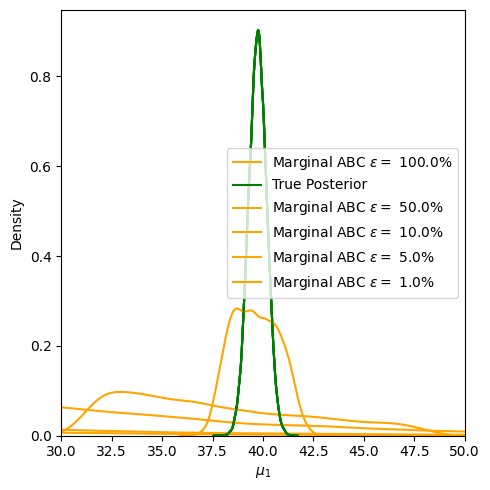

In [4]:
xlims = [[30, 50]]
plot_quantiles(all_datas, estimators, abc = True, nre = False, correct_nre = False, true = True, n_samples=100000, marginal=True, joint=False, xlims=xlims)


(100000, 1)


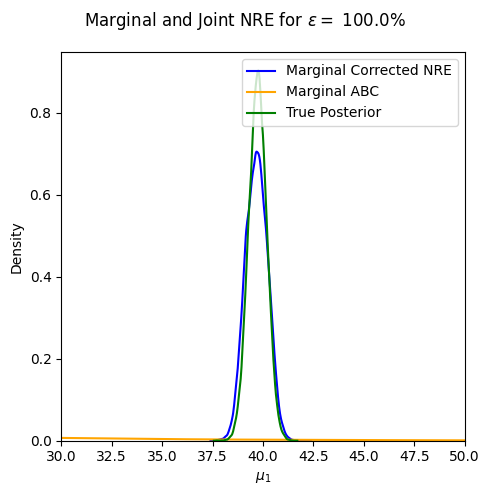

(100000, 1)


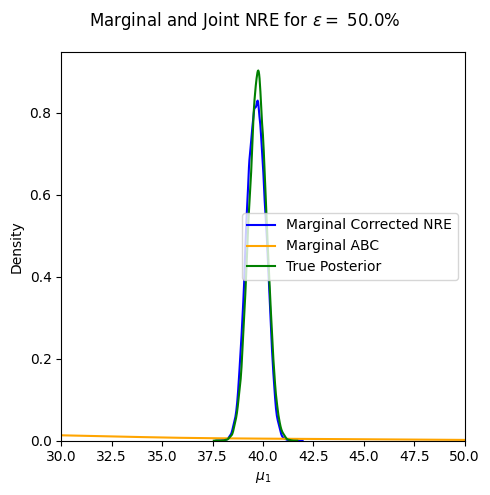

(100000, 1)


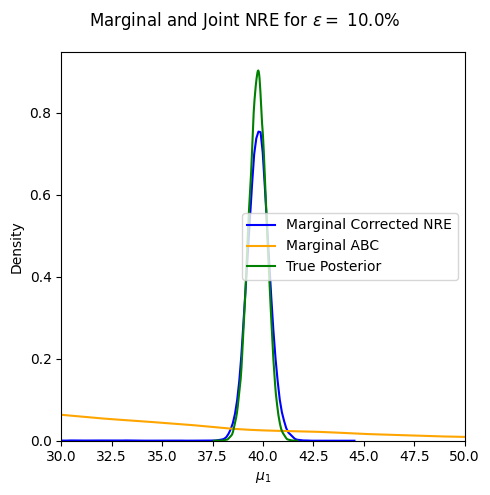

(100000, 1)


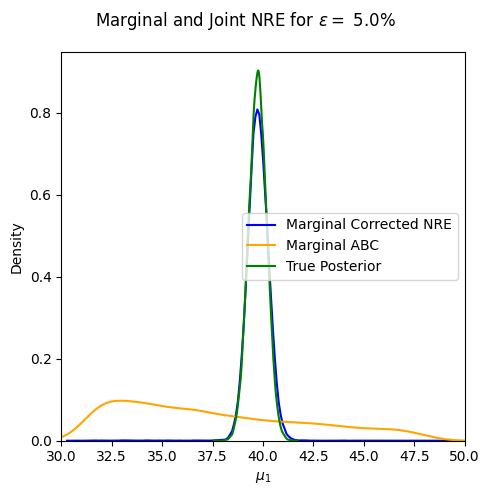

(100000, 1)


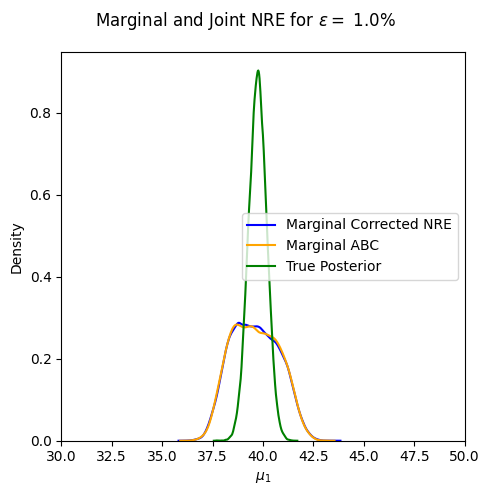

In [5]:
plot_marginals(all_datas, estimators, abc = True, nre = False, correct_nre = True, true = True, n_samples=100000, xlims=xlims, joint = False)

(100000, 1)


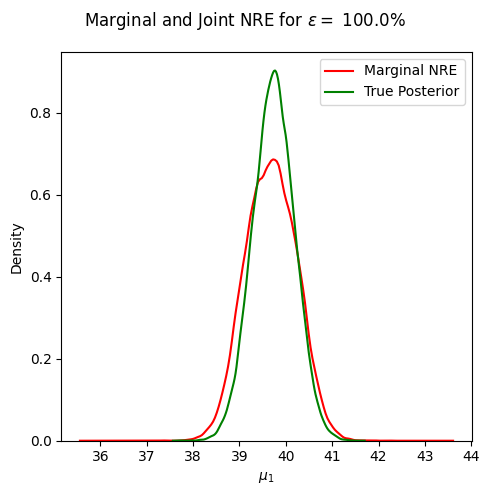

(100000, 1)


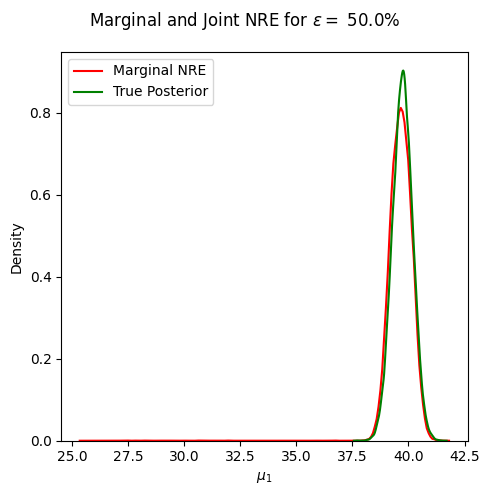

(100000, 1)


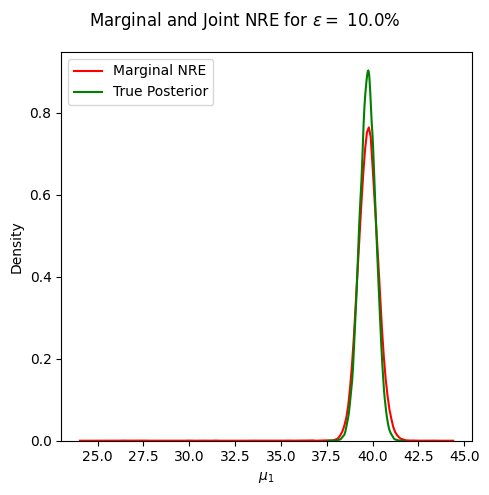

(100000, 1)


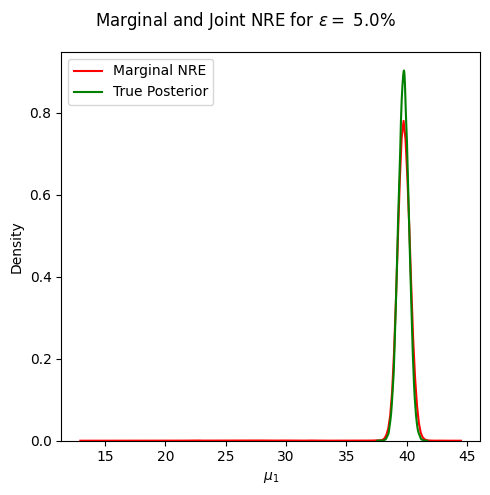

(100000, 1)


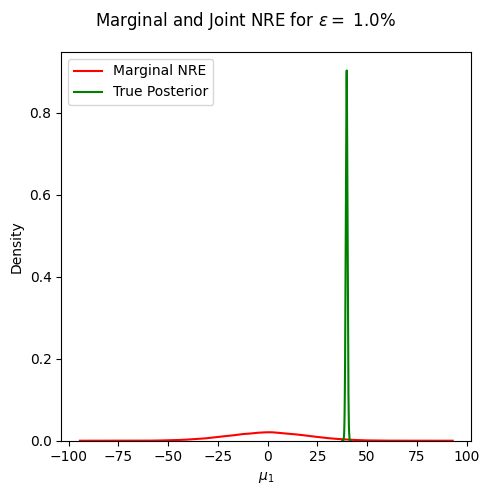

In [6]:

plot_marginals(all_datas, estimators, abc = False, nre = True, correct_nre = False, true = True, n_samples=100000,  joint = False)

(100000, 1)


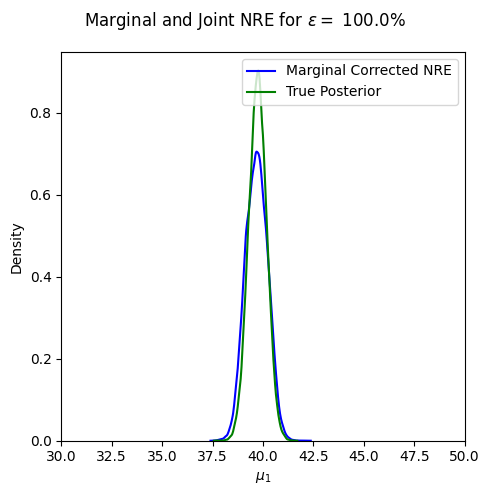

(100000, 1)


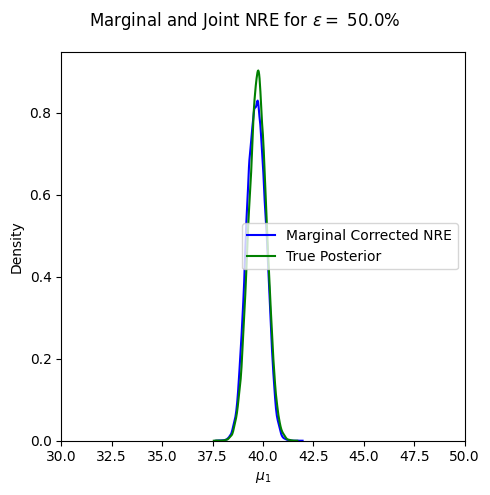

(100000, 1)


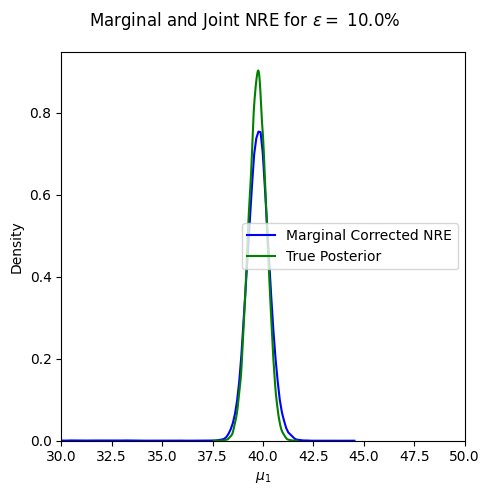

(100000, 1)


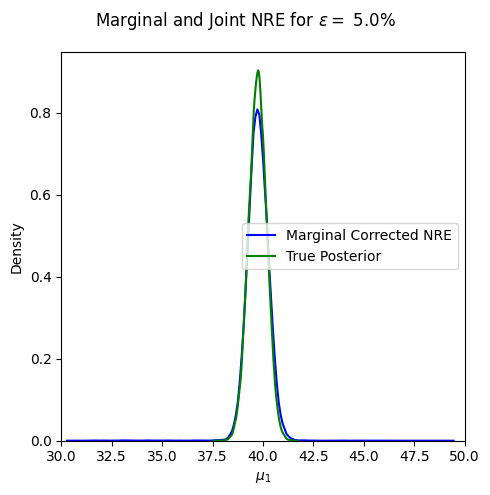

(100000, 1)


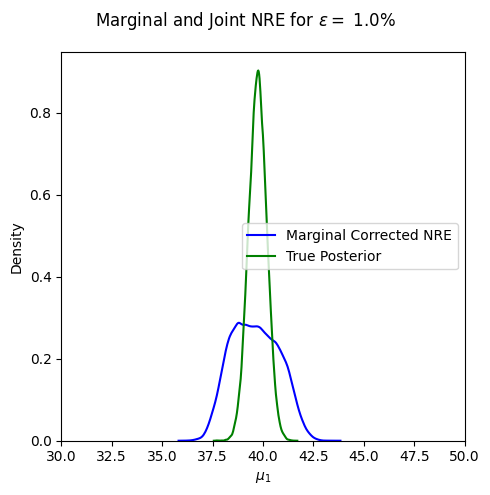

In [7]:
plot_marginals(all_datas, estimators, abc = False, nre = False, correct_nre = True, true = True, n_samples=100000, xlims=xlims, joint = False)

# grid

In [8]:
grid_PATH = RESULTS_PATH / "grids/"

all_grids = {}
for quantile in quantiles:
    all_grids[quantile] = {}
    for marginal in marginals:
        all_grids[quantile][marginal] = np.load(grid_PATH / f"grid_marginal_{marginal}_quantile_{quantile}.npz", allow_pickle=True)["arr_0"].item()
all_grids["true_posterior"] = np.load(grid_PATH / "grid_true.npz", allow_pickle=True)["arr_0"].item()["true_posterior"]


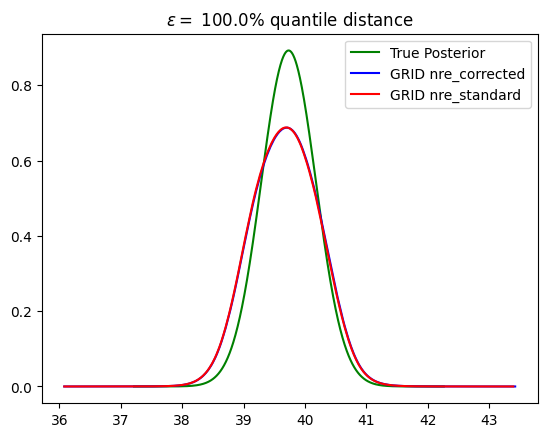

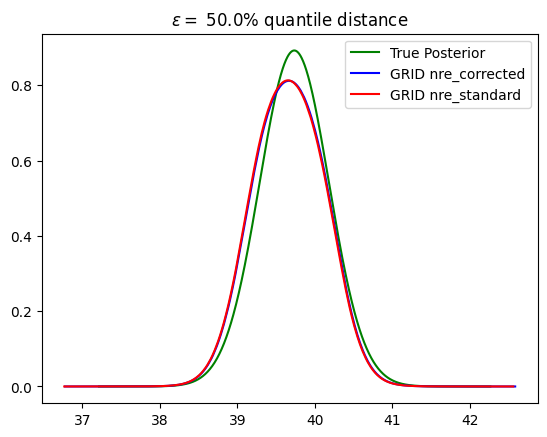

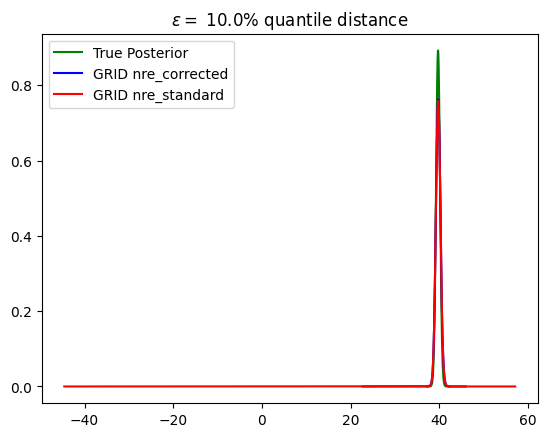

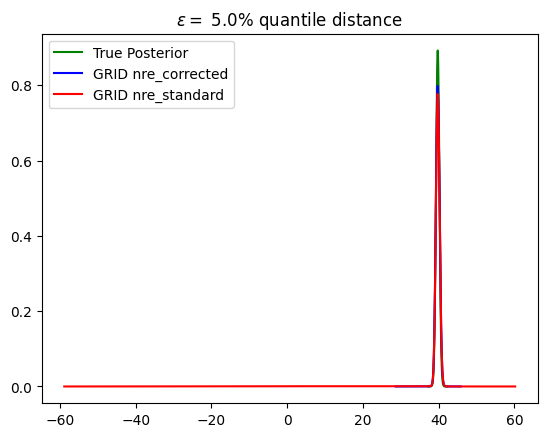

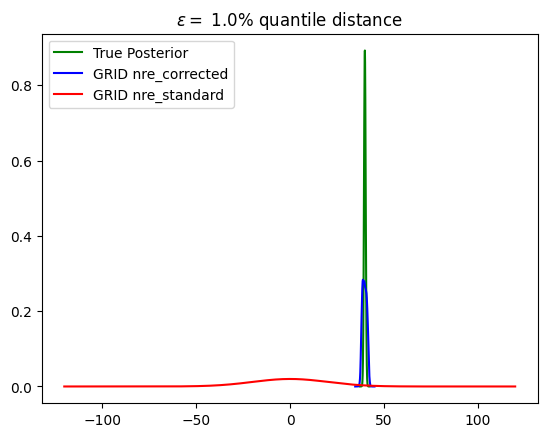

In [9]:
methods = ["nre_corrected","nre_standard"]
colors = ["blue", "red"]
true_results = all_grids["true_posterior"]
true_grid, true_pdf = true_results["grid"], true_results["pdf"]
for quantile in quantiles:
    plt.plot(true_grid, true_pdf, color="green", label="True Posterior")
    # sns.kdeplot(all_datas["true_posterior"].flatten(), label="MCMC True Posterior", color="green", linestyle="--")
    for marginal in marginals:
        for method, color in zip(methods, colors):
            plt.plot(all_grids[quantile][marginal][method]["grid"], all_grids[quantile][marginal][method]["pdf"], color=color, label=f"GRID {method}")
            # sns.kdeplot(all_datas[quantile][marginal][method].flatten(), label=f"MCMC {method}", color=color, linestyle="--")
        plt.title(f"$\epsilon =$ {quantile:.1%} quantile distance")
        plt.legend()
        plt.show()

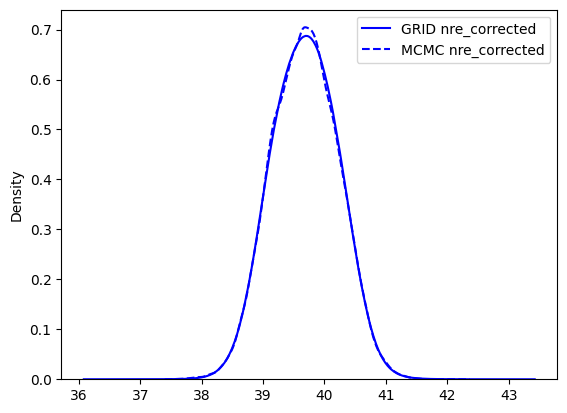

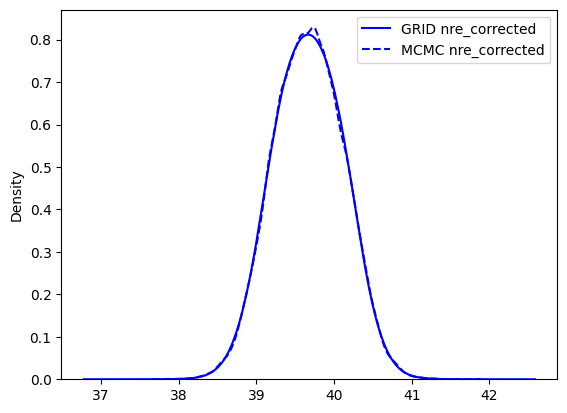

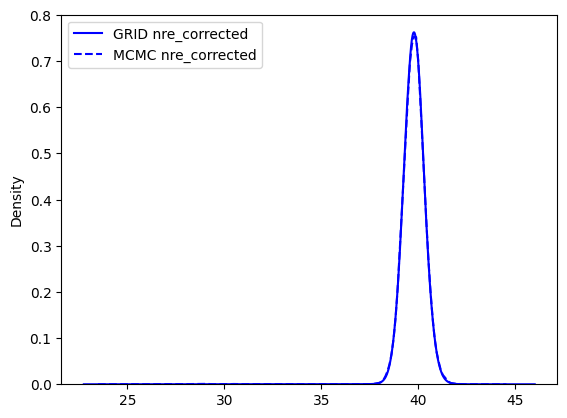

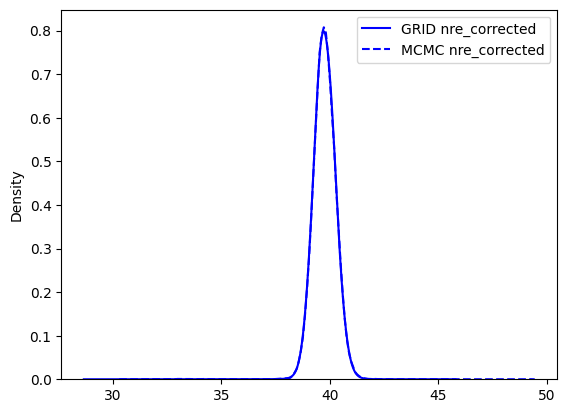

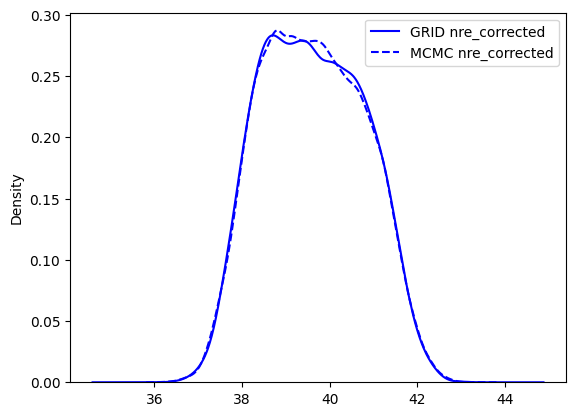

In [10]:
methods = ["nre_corrected",]
colors = ["blue"]
true_results = all_grids["true_posterior"]
true_grid, true_pdf = true_results["grid"], true_results["pdf"]
for quantile in quantiles:
    for marginal in marginals:
        for method, color in zip(methods, colors):
            plt.plot(all_grids[quantile][marginal][method]["grid"], all_grids[quantile][marginal][method]["pdf"], color=color, label=f"GRID {method}")
            sns.kdeplot(all_datas[quantile][marginal][method].flatten(), label=f"MCMC {method}", color=color, linestyle="--")
        plt.legend()
        plt.show()

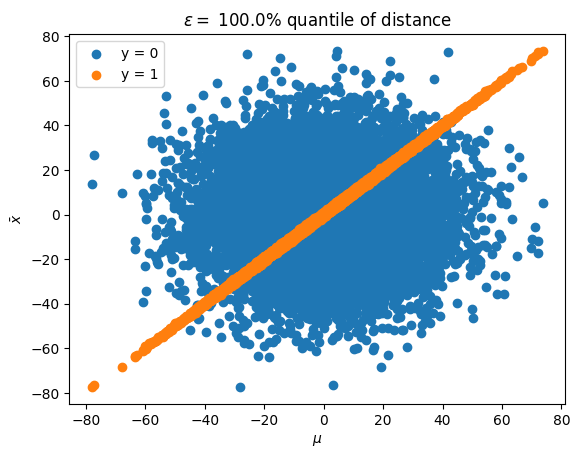

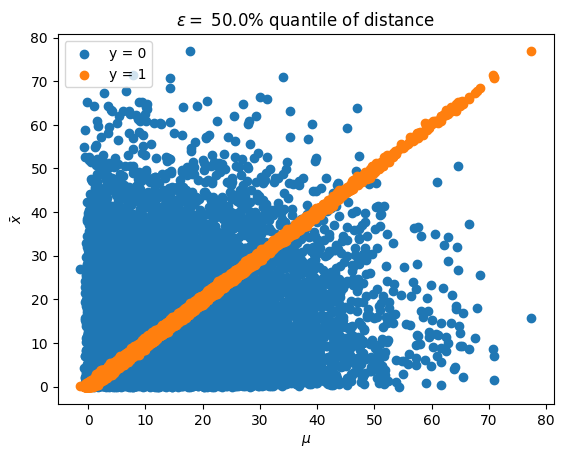

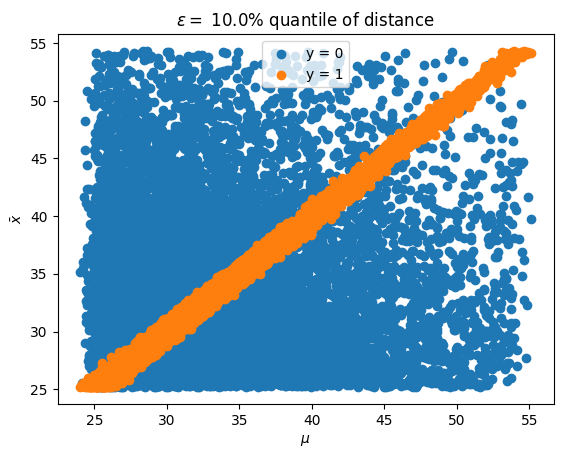

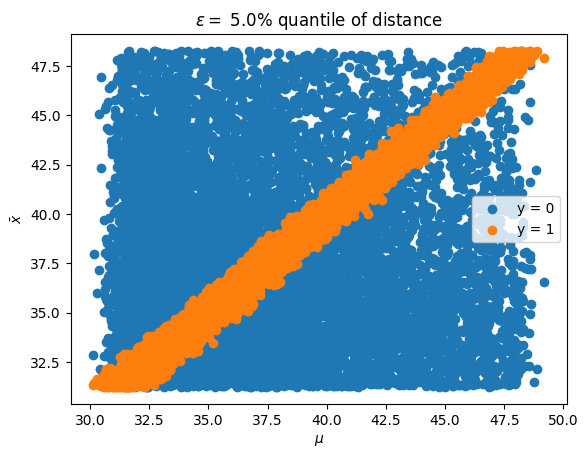

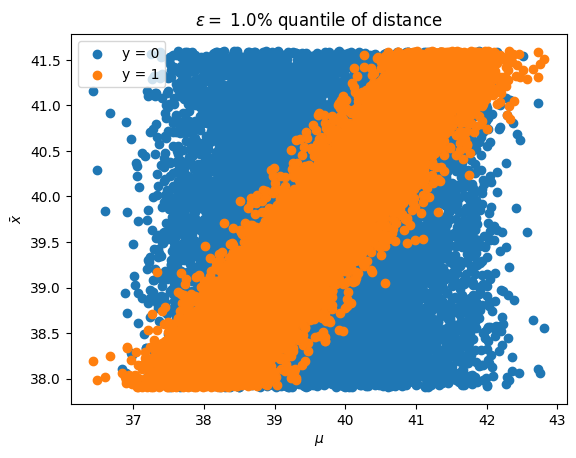

In [11]:
key = jax.random.PRNGKey(0)
for quantile in quantiles: 
    estimator = estimators[quantile][0]
    key, subkey = jax.random.split(key)
    results = estimator.simulator.generate_training_samples(subkey, 20000)
    labels = results.labels
    phis = results.phi
    xs = results.data
    plt.scatter(phis[labels == 0], np.mean(xs[labels ==0], axis = 1), label = "y = 0")
    plt.scatter(phis[labels == 1], np.mean(xs[labels ==1], axis = 1), label = "y = 1")
    plt.legend()
    plt.xlabel("$\\mu$")
    plt.ylabel("$\\bar{x}$")
    plt.title(f"$\epsilon =$ {quantile:.1%} quantile of distance")
    plt.show()

# Computing the true ratio 

In [12]:
from scipy.stats import norm
def abc_posterior_pdf(mu, n_obs, mean_obs, sigma, sigma0, epsilon):
    return norm.pdf(mu, loc = 0, scale = sigma0)*(norm.cdf((mean_obs+ epsilon -mu)/sigma*np.sqrt(n_obs)) - norm.cdf((mean_obs - epsilon -mu)/sigma*np.sqrt(n_obs)))/(norm.cdf((mean_obs + epsilon - 0) / np.sqrt(sigma0**2 + sigma**2/n_obs)) - norm.cdf((mean_obs - epsilon - 0) / np.sqrt(sigma0**2 + sigma**2/n_obs)))


def true_posterior_pdf(mu, n_obs, mean_obs, sigma, sigma0):
    sigma_n = np.sqrt(1 / (n_obs/sigma**2 + 1/sigma0**2))
    mu_n = (n_obs * mean_obs/sigma**2)*sigma_n**2
    return norm.pdf(mu, loc=mu_n, scale=sigma_n)

def ratio_true_abc(mu, n_obs, mean_obs, sigma, sigma0, epsilon):
    abc_pdf = abc_posterior_pdf(mu, n_obs, mean_obs, sigma, sigma0, epsilon)
    true_pdf = true_posterior_pdf(mu, n_obs, mean_obs, sigma, sigma0)
    # Avoid division by zero and invalid values
    ratio = np.zeros_like(true_pdf)
    valid = np.logical_and(abc_pdf > 0, true_pdf > 0)
    ratio[valid] = true_pdf[valid] / abc_pdf[valid]
    return ratio

In [13]:
sigma = estimator.simulator.model.sigma
sigma0 = estimator.simulator.model.sigma0
n_obs = estimator.simulator.model.n_obs
mean_obs = estimator.simulator.observed_summary_stats

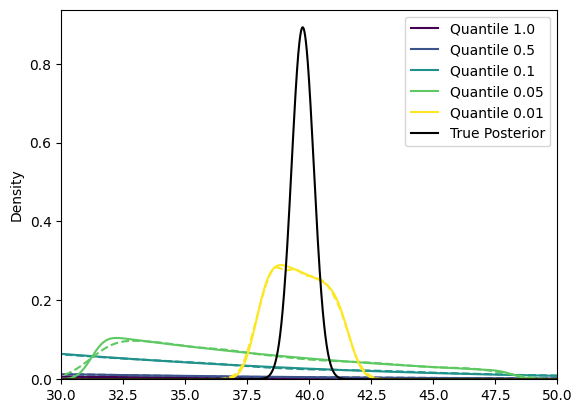

In [14]:
colors = plt.cm.viridis(np.linspace(0, 1, len(quantiles)))
for i, quantile in enumerate(quantiles):
    epsilon = estimators[quantile][0].simulator.epsilon
    mus = np.linspace(30, 50, 10000)
    abc_pdf = abc_posterior_pdf(mus, n_obs, mean_obs, sigma, sigma0, epsilon)
    plt.plot(mus, abc_pdf, label=f"Quantile {quantile}", color = colors[i])
    sns.kdeplot(estimators[quantile][0].stored_phis.flatten(), color=colors[i], linestyle='--')

plt.plot(mus, true_posterior_pdf(mus, n_obs, mean_obs, sigma, sigma0), label="True Posterior", color="black")
plt.xlim(30, 50)
plt.legend()

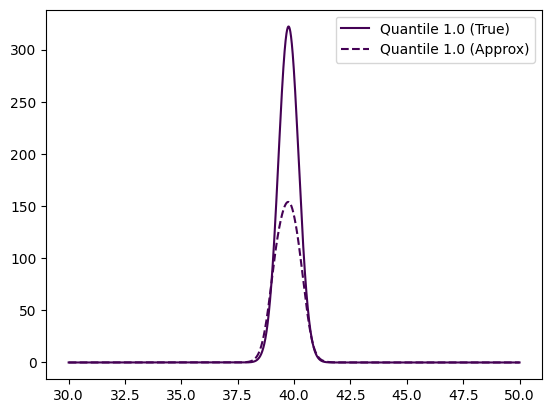

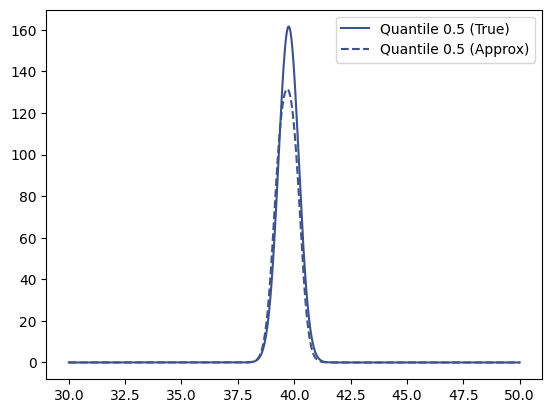

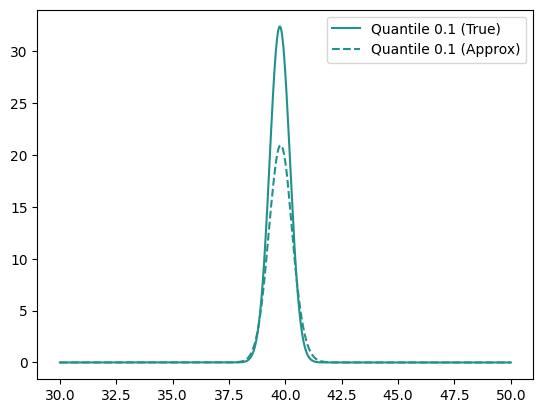

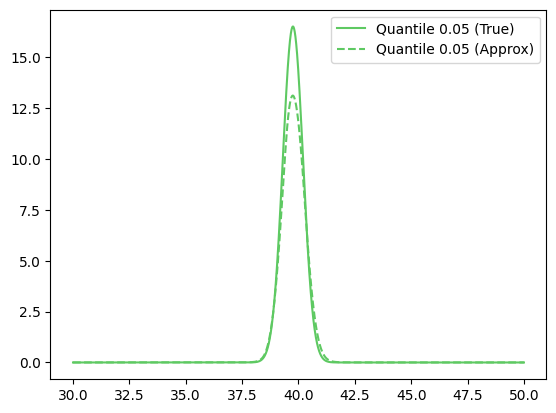

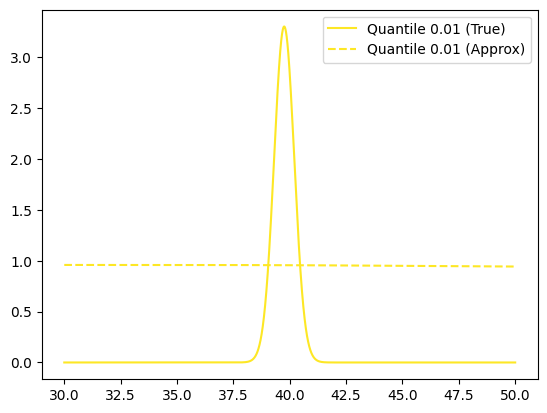

In [15]:
colors = plt.cm.viridis(np.linspace(0, 1, len(quantiles)))
from abcnre.diagnostics import get_ratio_unnormalized_pdf

for i, quantile in enumerate(quantiles):
    epsilon = estimators[quantile][0].simulator.epsilon
    mus = np.linspace(30, 50, 10000)
    true_ratio = ratio_true_abc(mus, n_obs, mean_obs, sigma, sigma0, epsilon)
    approx_ratio_func = get_ratio_unnormalized_pdf(estimators[quantile][0])
    approx_ratio = approx_ratio_func(mus)
    plt.plot(mus, true_ratio, label=f"Quantile {quantile} (True)", color=colors[i])
    plt.plot(mus, approx_ratio, label=f"Quantile {quantile} (Approx)", linestyle='dashed', color=colors[i])
    plt.legend()
    plt.show()
